# Importar Bibliotecas Necesarias
Importar pandas, numpy, sklearn (Pipeline, RandomForestClassifier, OneHotEncoder, SimpleImputer, train_test_split, classification_report, accuracy_score), joblib y las funciones personalizadas necesarias de los módulos utils.

In [4]:
import pandas as pd
import numpy as np
from statistics import mean
import os
import sys
import joblib # For saving the model
import json
from datetime import timezone

# Scikit-learn imports
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# Ruta absoluta al directorio src
src_path = os.path.abspath("../src") # Adjust if the notebook location changes relative to src
if src_path not in sys.path:
    sys.path.append(src_path)

# Import custom utility functions
from utils.exploration_utils import (
    read_csv_files,
    preprocess_data,
    generate_target_variable,
    engineer_features
)
from utils.support_resistance import calculate_progressive_support_resistance, calcular_metricas_fila
from utils.viz_utils import plot_candlestick_with_clusters_plotly, analizar_metricas_por_umbral
from sklearn.cluster import KMeans # For clustering steps if included in pipeline

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100) # Adjust as needed

# Cargar Datos Iniciales
Cargar el conjunto de datos principal (por ejemplo, desde un archivo parquet '../data/parquet/EURUSD/EURUSD_5mins.parquet').

In [5]:
# Read Data from CSV files:
folder_path = '../data/EURUSD/5mins' # Define the folder containing CSV files
print(f"Attempting to load data from CSV files in: {folder_path}")
import pytz # Ensure pytz is imported if used in checks

try:
    # Check if the directory exists
    if not os.path.isdir(folder_path):
         raise FileNotFoundError(f"Error: Directory not found at {folder_path}. Please check the path.")

    df_EURUSD_5min = read_csv_files(folder_path) # Use the utility function to read CSVs

    # Check if data was loaded
    if df_EURUSD_5min.empty:
        print("Warning: No data loaded. The DataFrame is empty. Check the CSV files or the read_csv_files function.")
    else:
        print(f"Data loaded successfully from CSVs in {folder_path}")
        print(f"Initial DataFrame shape: {df_EURUSD_5min.shape}")

        # Apply preprocessing (includes timezone parsing and UTC conversion)
        print("Applying preprocessing (preprocess_data)...")
        # preprocess_data now handles parsing 'YYYYMMDD HH:MM:SS TZ' and converting to UTC
        df_EURUSD_5min = preprocess_data(df_EURUSD_5min)
        print(f"DataFrame shape after preprocess_data: {df_EURUSD_5min.shape}")

        # Verify the result of preprocess_data
        if 'datetime' not in df_EURUSD_5min.columns:
             raise KeyError("Critical Error: 'datetime' column not found after preprocess_data.")
        if not pd.api.types.is_datetime64_any_dtype(df_EURUSD_5min['datetime']):
             print("Warning: 'datetime' column is not in a recognized datetime format after preprocess_data.")
        # Check if the timezone is specifically UTC
        elif df_EURUSD_5min['datetime'].dt.tz is None or df_EURUSD_5min['datetime'].dt.tz != timezone.utc:
             print(f"Warning: 'datetime' column is not timezone-aware UTC after preprocess_data. Found: {df_EURUSD_5min['datetime'].dt.tz}")
        else:
             print("'datetime' column successfully processed to timezone-aware UTC by preprocess_data.")

        # Optional: Check for NaT values introduced during preprocessing
        nat_count = df_EURUSD_5min['datetime'].isna().sum()
        if nat_count > 0:
            print(f"Warning: {nat_count} rows have NaT in 'datetime' after preprocessing. Consider dropping them if necessary.")
            # df_EURUSD_5min.dropna(subset=['datetime'], inplace=True)

        # Sorting is already done inside preprocess_data, no need to repeat
        print("DataFrame is sorted by UTC datetime within preprocess_data.")

except FileNotFoundError as fnf_error:
     print(fnf_error)
     raise # Re-raise the exception to stop the notebook if the directory is critical

except KeyError as ke:
     print(ke) # Print the specific KeyError message
     raise # Re-raise to indicate failure

except Exception as e:
    print(f"An unexpected error occurred during data loading or preprocessing: {e}")
    import traceback
    traceback.print_exc() # Print full traceback for unexpected errors
    raise # Re-raise to indicate failure

# Display head if data loaded successfully
if 'df_EURUSD_5min' in locals() and not df_EURUSD_5min.empty:
    print("\nDisplaying first few rows of the loaded and preprocessed data (datetime is UTC):")
    df_EURUSD_5min.head()
else:
    print("\nCould not display head as DataFrame is not available or empty.")

Attempting to load data from CSV files in: ../data/EURUSD/5mins
Data loaded successfully from CSVs in ../data/EURUSD/5mins
Initial DataFrame shape: (1105411, 7)
Applying preprocessing (preprocess_data)...
Starting preprocessing...
Convirtiendo fechas/horas parseadas a UTC...
Extrayendo componentes de fecha/hora desde UTC...
Ordenando DataFrame por fecha/hora UTC...
Preprocesamiento completado. DataFrame ordenado por fecha/hora UTC.
DataFrame shape after preprocess_data: (1105411, 14)
'datetime' column successfully processed to timezone-aware UTC by preprocess_data.
DataFrame is sorted by UTC datetime within preprocess_data.

Displaying first few rows of the loaded and preprocessed data (datetime is UTC):


In [6]:
df_EURUSD_5min.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1105411 entries, 0 to 1105410
Data columns (total 14 columns):
 #   Column     Non-Null Count    Dtype              
---  ------     --------------    -----              
 0   open       1105411 non-null  float64            
 1   high       1105411 non-null  float64            
 2   low        1105411 non-null  float64            
 3   close      1105411 non-null  float64            
 4   volume     1105411 non-null  int64              
 5   barCount   1105411 non-null  int64              
 6   datetime   1105411 non-null  datetime64[ns, UTC]
 7   Year       1105411 non-null  int32              
 8   Month      1105411 non-null  object             
 9   Day        1105411 non-null  int32              
 10  Date       1105411 non-null  object             
 11  Hour       1105411 non-null  int32              
 12  Minute     1105411 non-null  int32              
 13  DayOfWeek  1105411 non-null  int32              
dtypes: datetime64[ns, 

In [11]:
# --- BLOQUE 1: DATOS Y SPLIT (Arquitectura Robusta) ---
# En lugar de crear X_train "mutilado" aquí, creamos df_train COMPLETO.

TARGET_VAR_BUY = 'target_buy'
TARGET_VAR_SELL = 'target_sell'

# Ordenar por tiempo (seguridad)
df_EURUSD_5min = df_EURUSD_5min.sort_values('datetime').reset_index(drop=True)

PIPS_OBJETIVO_GENERACION = 25 
PIPS_STOP_GENERACION = 10    
FUTURE_PERIODS = 18          

# Generar targets (modifica df_processed)
df_processed = generate_target_variable(df_EURUSD_5min.copy(), 
                                        pips_objetivo=PIPS_OBJETIVO_GENERACION, 
                                        pips_stop=PIPS_STOP_GENERACION, 
                                        future_periods=FUTURE_PERIODS)

# Crear Targets Binarios
df_processed[TARGET_VAR_BUY] = (df_processed['compra_resultado'] == 'OBJETIVO_ALCANZADO').astype(int)
df_processed[TARGET_VAR_SELL] = (df_processed['venta_resultado'] == 'OBJETIVO_ALCANZADO').astype(int)

# Limpieza inicial (solo filas inválidas por falta de futuro)
df_processed = df_processed.dropna(subset=['compra_resultado', 'venta_resultado'])
df_processed = df_processed.dropna(subset=['future_high_values', 'future_low_values', 'future_close_values'], how='any')

# Definir Fechas de Corte
split_date_train_end = "2023-12-31" 
split_date_test_end = "2024-12-31"

if df_processed['datetime'].dt.tz is not None:
    tz_info = df_processed['datetime'].dt.tz
    split_datetime_train_end = pd.Timestamp(split_date_train_end, tz=tz_info).replace(hour=23, minute=59, second=59)
    split_datetime_test_end = pd.Timestamp(split_date_test_end, tz=tz_info).replace(hour=23, minute=59, second=59)
else:
    split_datetime_train_end = pd.Timestamp(split_date_train_end).replace(hour=23, minute=59, second=59)
    split_datetime_test_end = pd.Timestamp(split_date_test_end).replace(hour=23, minute=59, second=59)

# DIVIDIR manteniendo TODAS las columnas (precios incluidos)
df_train = df_processed[df_processed['datetime'] <= split_datetime_train_end].copy()
df_test = df_processed[(df_processed['datetime'] > split_datetime_train_end) & (df_processed['datetime'] <= split_datetime_test_end)].copy()
df_oot = df_processed[df_processed['datetime'] > split_datetime_test_end].copy()

# Configuración de Debug (se usará en la siguiente celda)
DEBUG_MODE = False 
DEBUG_SAMPLE_SIZE = 50000 

print(f"Data split completed (Raw DataFrames).")
print(f"   Train rows: {len(df_train)}")
print(f"   Test rows:  {len(df_test)}")
print(f"   OOT rows:   {len(df_oot)}")
print(f"   Debug Mode: {DEBUG_MODE}")

Generating target variable (pips_objetivo=25, pips_stop=10, future_periods=18)...
Evaluating trading scenarios...
Target variable 'multiclass_target' created.
Data split completed (Raw DataFrames).
   Train rows: 1009598
   Test rows:  72449
   OOT rows:   23364
   Debug Mode: False


In [ ]:
# --- Reemplazar contenido de la celda de Configuración de Modelos ---

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import TruncatedSVD 

# --- Preprocesadores ---

# Numerical Preprocessor (para columnas numéricas estándar)
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

# Categorical Preprocessor (para OHE de otras variables categóricas si las hay)
categorical_ohe_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# --- Pattern Embedding Transformer (SVD) ---
N_EMBEDDING_COMPONENTS = 30 # Ajustable

pattern_embedding_transformer = Pipeline(steps=[
    # Paso 1: Imputar NaNs
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    # Paso 2: OneHotEncode la columna 'pattern'. Salida dispersa es eficiente aquí.
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=True)),
    # Paso 3: Aplicar TruncatedSVD para reducir dimensionalidad y crear embeddings densos
    ('svd', TruncatedSVD(n_components=N_EMBEDDING_COMPONENTS, random_state=42))
])

# --- Define Base Model (se usará clona para Buy y Sell) ---
# Configuramos el modelo base. Luego crearemos dos copias (una para cada pipeline).
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    min_samples_split=100,
    random_state=42,
    n_jobs=-1,
    class_weight='balanced',
    max_features='sqrt'
)

print("Pipeline components defined (numeric_transformer, categorical_ohe_transformer, pattern_embedding_transformer).")
print(f"Pattern Embedding (SVD) set to {N_EMBEDDING_COMPONENTS} components.")
print("rf_model base defined. It will be cloned for both 'pipeline_buy' and 'pipeline_sell'.")

Pipeline components defined (numeric_transformer, categorical_ohe_transformer, pattern_embedding_transformer).
Pattern Embedding (SVD) set to 30 components.
rf_model base defined. It will be cloned for both 'pipeline_buy' and 'pipeline_sell'.


In [19]:
# --- BLOQUE 2: ENTRENAMIENTO ROBUSTO Y CALIBRADO ---

import importlib
import utils.exploration_utils
importlib.reload(utils.exploration_utils)
from utils.exploration_utils import engineer_features
import traceback
import os
import joblib
import json
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV

print("--- Dual Model Training (Calibrated & Robust) ---")

# Parámetros y Rutas (Igual que antes)
N_CANDLES_PARAM = 15
N_CLUSTERS_PARAM = 5
model_dir = '../models/EURUSD'
clusterer_filepath = os.path.join(model_dir, 'forex_candle_clusterer_eurusd_5mins.joblib')
# Cambiamos nombre para indicar que son calibrados
model_buy_filepath = os.path.join(model_dir, 'forex_rf_pipeline_eurusd_5mins_BUY_calibrated.joblib')
model_sell_filepath = os.path.join(model_dir, 'forex_rf_pipeline_eurusd_5mins_SELL_calibrated.joblib')
metadata_buy_filepath = os.path.join(model_dir, 'forex_rf_pipeline_eurusd_5min_BUY_calibrated_metadata.json')
metadata_sell_filepath = os.path.join(model_dir, 'forex_rf_pipeline_eurusd_5min_SELL_calibrated_metadata.json')

if not os.path.exists(model_dir): os.makedirs(model_dir)

models_loaded = False
pipeline_buy = None
pipeline_sell = None

# A. Cargar (Omitido por brevedad, usa lógica similar a antes si la necesitas)

# B. Entrenar (Si no se cargó)
if not models_loaded:
    print("\nStarting Calibrated Training Workflow...")
    
    # 1. INPUT (Debug logic)
    if 'DEBUG_MODE' in locals() and DEBUG_MODE:
         df_input = df_train.sample(n=min(DEBUG_SAMPLE_SIZE, len(df_train)), random_state=42).sort_index()
    else:
         df_input = df_train.copy()

    try:
        # 2. FEATURE ENGINEERING
        df_engineered, fitted_clusterer = engineer_features(
            df_input, n_candles=N_CANDLES_PARAM, n_clusters=N_CLUSTERS_PARAM, 
            min_pattern_threshold=100, fit_clusterer=True, random_state=42
        )
        
        # 3. LIMPIEZA
        valid_idx = df_engineered.dropna(subset=['pattern']).index
        df_clean = df_engineered.loc[valid_idx]
        y_buy_clean = df_clean[TARGET_VAR_BUY]
        y_sell_clean = df_clean[TARGET_VAR_SELL]
        
        cols_to_drop = [
            'datetime', 'open', 'close', 'high', 'low', 'volume', 'Date',
            'barCount', 'Year', 'Minute', 
            TARGET_VAR_BUY, TARGET_VAR_SELL, 'multiclass_target',
            'compra_resultado', 'venta_resultado', 'compra_velas', 'venta_velas', 'compra_pips', 'venta_pips',
            'future_high_values', 'future_low_values', 'future_close_values'
        ]
        cols_to_drop += [c for c in df_clean.columns if c.startswith('future_') or c.startswith('target_')]
        X_train_final = df_clean.drop(columns=cols_to_drop, errors='ignore')

        # 4. PREPROCESADOR
        potential_num = X_train_final.select_dtypes(include=np.number).columns.tolist()
        other_cat = [c for c in ['DayOfWeek', 'Month', 'Day', 'Hour', 'candle_cluster'] if c in X_train_final.columns]
        pattern_feat = ['pattern'] if 'pattern' in X_train_final.columns else []
        final_num = [c for c in potential_num if c not in other_cat and c not in pattern_feat]

        transformers = [('num', numeric_transformer, final_num)]
        if other_cat: transformers.append(('cat_ohe', categorical_ohe_transformer, other_cat))
        if pattern_feat: transformers.append(('pattern_embed', pattern_embedding_transformer, pattern_feat))
        preprocessor = ColumnTransformer(transformers, remainder='drop', verbose=False)

        # 5. MODELOS CALIBRADOS (La Novedad)
        print("   Training Models with Calibration...")
        
        # Envolvemos el RF en CalibratedClassifierCV
        base_rf = clone(rf_model)
        calibrated_clf = CalibratedClassifierCV(base_rf, method='isotonic', cv=3) 

        print("      Training BUY Model (Calibrated)...")
        pipeline_buy = Pipeline([('preprocessing', preprocessor), ('classifier', clone(calibrated_clf))])
        pipeline_buy.fit(X_train_final, y_buy_clean)
        
        print("      Training SELL Model (Calibrated)...")
        pipeline_sell = Pipeline([('preprocessing', preprocessor), ('classifier', clone(calibrated_clf))])
        pipeline_sell.fit(X_train_final, y_sell_clean)

        # 6. GUARDAR
        print("   Saving Calibrated Artifacts...")
        joblib.dump(pipeline_buy, model_buy_filepath)
        joblib.dump(pipeline_sell, model_sell_filepath)
        joblib.dump(fitted_clusterer, clusterer_filepath)
        print("\n--- Calibrated Training Completed ---")

    except Exception as e:
        print(f"CRITICAL ERROR: {e}")
        traceback.print_exc()

--- Dual Model Training (Calibrated & Robust) ---

Starting Calibrated Training Workflow...
--- Starting Feature Engineering ---
>>> Starting step: apply_technical_indicators
<<< Finished step: apply_technical_indicators
>>> Starting step: apply_candle_features (n_candles=15)
<<< Finished step: apply_candle_features
   Fitting and transforming with NEW CandleClusterer...
>>> Starting step: CandleClusterer.fit (k=5)
   KMeans fitted.
   Fitting pattern mapping...
   Pattern mapping created. 0 rare patterns will be mapped.
<<< Finished step: CandleClusterer.fit
>>> Starting step: CandleClusterer.transform
   Candle clusters predicted.
   Basic patterns created.
   No pattern mapping to apply (or mapping is empty).
<<< Finished step: CandleClusterer.transform
>>> Starting step: replace_inf_with_nan
  Columns initially identified as numeric: ['open', 'high', 'low', 'close', 'volume', 'barCount', 'Year', 'Day', 'Hour', 'Minute', 'DayOfWeek', 'compra_velas', 'compra_pips', 'venta_velas', 've

In [20]:
# --- Reemplazar contenido de Evaluacion Train vs Test (Dual Model) ---

print("Applying feature engineering to Train and Test sets for evaluation...")

try:
    # --- 1. Aplicar Ingeniería (usando df_train / df_test que tienen precios) ---
    # Nota: Usamos fitted_clusterer que ya se ajustó en el paso de entrenamiento
    
    # Train (Ya lo teniamos del paso anterior, pero lo recreamos para asegurar consistencia en evaluación)
    # Si memoria es problema, podriamos reusar df_engineered del paso anterior si existe
    if 'df_engineered' in locals():
        df_eng_train_eval = df_engineered
    else:
        df_eng_train_eval, _ = engineer_features(df_train, n_candles=N_CANDLES_PARAM, n_clusters=N_CLUSTERS_PARAM, clusterer=fitted_clusterer, fit_clusterer=False)

    # Test (Nuevo)
    df_eng_test_eval, _ = engineer_features(df_test, n_candles=N_CANDLES_PARAM, n_clusters=N_CLUSTERS_PARAM, clusterer=fitted_clusterer, fit_clusterer=False)

    # --- 2. Limpieza y Preparación de X ---
    # Funcion helper local para limpiar igual que en el entrenamiento
    def clean_for_eval(df_eng, target_buy_col, target_sell_col):
        # a. Filtrar filas inválidas
        valid_idx = df_eng.dropna(subset=['pattern']).index
        df_clean = df_eng.loc[valid_idx]
        
        # b. Columnas a borrar
        cols_drop = [
            'datetime', 'open', 'close', 'high', 'low', 'volume', 'Date',
            'barCount', 'Year', 'Minute', 
            target_buy_col, target_sell_col, 'multiclass_target',
            'compra_resultado', 'venta_resultado', 'compra_velas', 'venta_velas'
            # NO borrar 'compra_pips' o 'venta_pips' a ciegas si queremos features con _pips,
            # PERO 'compra_pips' y 'venta_pips' son targets en potencia. Agreguémoslos explícitamente:
            ,'compra_pips', 'venta_pips',
            'future_high_values', 'future_low_values', 'future_close_values'
        ]
        # Agregar dinámicamente SOLO future y targets reales
        cols_drop += [c for c in df_clean.columns if c.startswith('future_') or c.startswith('target_')]
        
        # NOTA: Borramos la condición c.endswith('_pips') porque borraba features útiles (distancias BB, etc.)
        
        X_clean = df_clean.drop(columns=cols_drop, errors='ignore')
        
        # c. Targets alineados
        y_buy = df_eng.loc[valid_idx, target_buy_col]
        y_sell = df_eng.loc[valid_idx, target_sell_col]
        
        return X_clean, y_buy, y_sell

    # Preparar Datos
    X_train_eval, y_train_buy_eval, y_train_sell_eval = clean_for_eval(df_eng_train_eval, TARGET_VAR_BUY, TARGET_VAR_SELL)
    X_test_eval, y_test_buy_eval, y_test_sell_eval = clean_for_eval(df_eng_test_eval, TARGET_VAR_BUY, TARGET_VAR_SELL)

    print(f"Eval Data Prepared. Train: {X_train_eval.shape}, Test: {X_test_eval.shape}")

    # --- 3. Evaluar Modelos ---
    from sklearn.metrics import accuracy_score, classification_report

    def print_eval_report(pipeline, X_tr, y_tr, X_te, y_te, name):
        print(f"\n{'='*40}")
        print(f"EVALUATION: {name}")
        print(f"{'='*40}")
        
        # Train
        y_pred_tr = pipeline.predict(X_tr)
        acc_tr = accuracy_score(y_tr, y_pred_tr)
        print(f"Train Accuracy: {acc_tr:.4f}")
        
        # Test
        y_pred_te = pipeline.predict(X_te)
        acc_te = accuracy_score(y_te, y_pred_te)
        print(f"Test Accuracy:  {acc_te:.4f}")
        
        if acc_tr > acc_te + 0.10:
             print(">> WARNING: Potential Overfitting detected (>10% gap)")
             
        print("\n--- Test Class Report ---")
        print(classification_report(y_te, y_pred_te))

    # Evaluar BUY
    if pipeline_buy:
        print_eval_report(pipeline_buy, X_train_eval, y_train_buy_eval, X_test_eval, y_test_buy_eval, "BUY MODEL")
    
    # Evaluar SELL
    if pipeline_sell:
        print_eval_report(pipeline_sell, X_train_eval, y_train_sell_eval, X_test_eval, y_test_sell_eval, "SELL MODEL")

except Exception as e:
    print(f"An error occurred during evaluation: {e}")
    import traceback
    traceback.print_exc()

Applying feature engineering to Train and Test sets for evaluation...
--- Starting Feature Engineering ---
>>> Starting step: apply_technical_indicators
<<< Finished step: apply_technical_indicators
>>> Starting step: apply_candle_features (n_candles=15)
<<< Finished step: apply_candle_features
   Transforming with PROVIDED CandleClusterer...
>>> Starting step: CandleClusterer.transform
   Candle clusters predicted.
   Basic patterns created.
   No pattern mapping to apply (or mapping is empty).
<<< Finished step: CandleClusterer.transform
>>> Starting step: replace_inf_with_nan
  Columns initially identified as numeric: ['open', 'high', 'low', 'close', 'volume', 'barCount', 'Year', 'Day', 'Hour', 'Minute', 'DayOfWeek', 'compra_velas', 'compra_pips', 'venta_velas', 'venta_pips', 'target_buy', 'target_sell', 'SMA_10', 'SMA_40', 'SMA_100', 'diff_SMA_10_SMA_40', 'ratio_SMA_10_SMA_40', 'ratio_SMA_40_SMA_10', 'diff_SMA_10_SMA_100', 'ratio_SMA_10_SMA_100', 'ratio_SMA_100_SMA_10', 'diff_SMA_4

# Analizar Importancia de Características

Extraer la importancia de las características del modelo RandomForest dentro del Pipeline. Visualizar las características más importantes.

*Nota:* Obtener los nombres correctos de las características después del `OneHotEncoder` requiere acceder al transformador dentro del `ColumnTransformer` del pipeline.

Analyzing Feature Importance for DUAL MODELS (Calibrated Support)...
   Extracting importances from CalibratedClassifierCV (averaging 3 folds)...


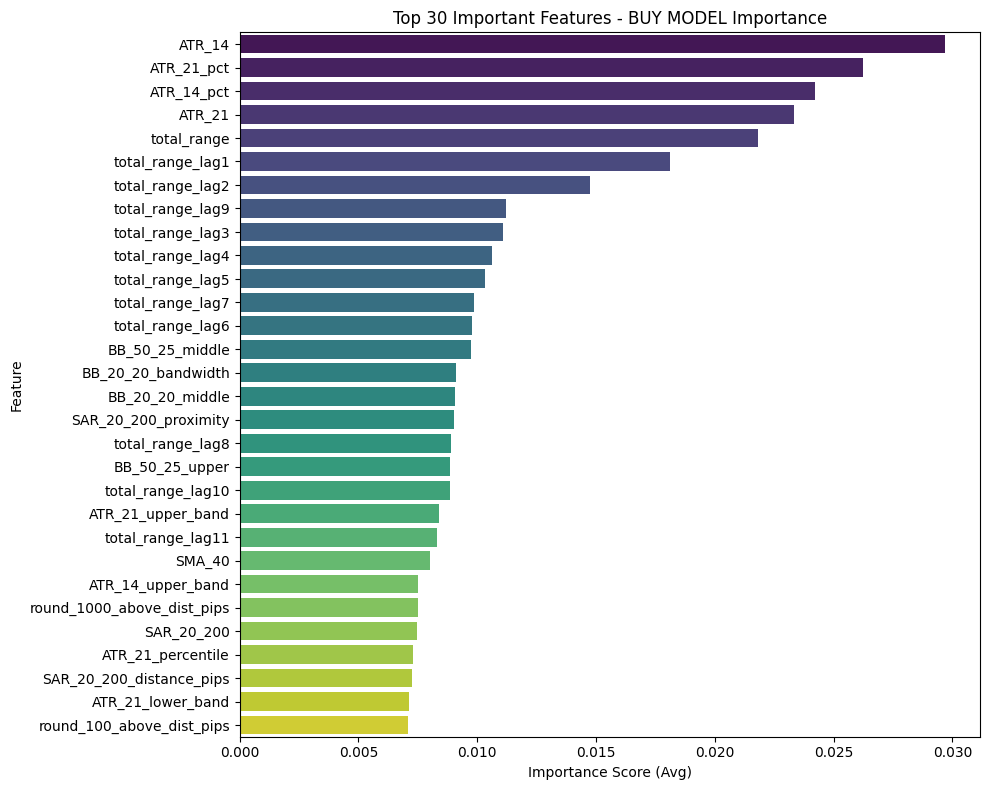

Top 5 Features:
    Feature  Importance
     ATR_14    0.029679
 ATR_21_pct    0.026244
 ATR_14_pct    0.024209
     ATR_21    0.023317
total_range    0.021813
   Extracting importances from CalibratedClassifierCV (averaging 3 folds)...


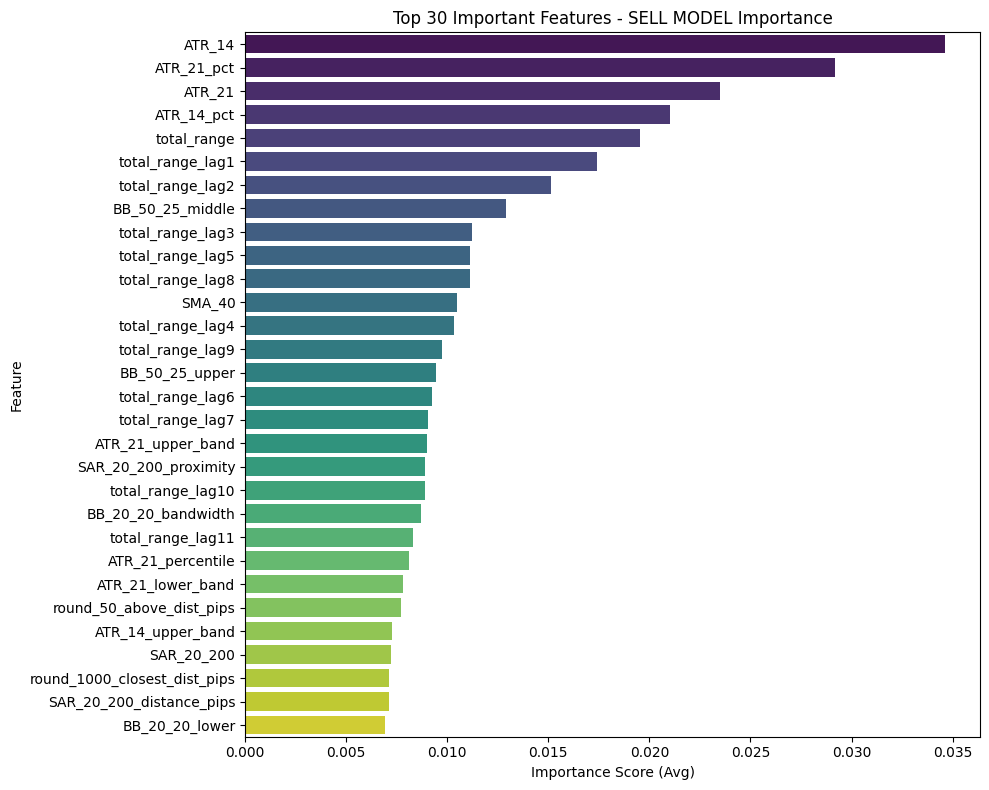

Top 5 Features:
    Feature  Importance
     ATR_14    0.034626
 ATR_21_pct    0.029162
     ATR_21    0.023483
 ATR_14_pct    0.020997
total_range    0.019524


In [24]:
# --- Reemplazar contenido de la celda de Feature Importance (Dual Model + Calibrated Support) ---
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import traceback
import numpy as np

print("Analyzing Feature Importance for DUAL MODELS (Calibrated Support)...")

def plot_pipeline_importance(pipeline, title="Feature Importance"):
    if pipeline is None:
        print(f"Skipping {title}: Pipeline is None.")
        return

    try:
        # 1. Acceder componentes
        preprocessor = pipeline.named_steps['preprocessing']
        classifier = pipeline.named_steps['classifier']

        # 2. Obtener nombres de features
        try:
            all_feature_names = preprocessor.get_feature_names_out()
            all_feature_names = [f.replace('num__', '').replace('cat_ohe__', '').replace('pattern_embed__', '') for f in all_feature_names]
            
        except AttributeError:
             print("Warning: get_feature_names_out() not available. Using fallback logic/indices.")
             # Si falla, no podemos graficar nombres, retornamos para evitar crash
             return

        # 3. Obtener Importancias (Lógica mejorada para CalibratedClassifierCV)
        importances = None
        
        # Caso A: Modelo estándar (RandomForest directo)
        if hasattr(classifier, 'feature_importances_'):
            importances = classifier.feature_importances_
            
        # Caso B: CalibratedClassifierCV
        elif hasattr(classifier, 'calibrated_classifiers_'):
            print(f"   Extracting importances from CalibratedClassifierCV (averaging {len(classifier.calibrated_classifiers_)} folds)...")
            imps_list = []
            for cal_clf in classifier.calibrated_classifiers_:
                # Acceder al estimador base dentro del calibrador
                # Sklearn varía: a veces es .estimator, a veces .base_estimator
                model_inner = getattr(cal_clf, 'estimator', getattr(cal_clf, 'base_estimator', None))
                
                if model_inner and hasattr(model_inner, 'feature_importances_'):
                    imps_list.append(model_inner.feature_importances_)
            
            if imps_list:
                # Promediar las importancias de todos los folds
                importances = np.mean(imps_list, axis=0)
            else:
                print("   Warning: Could not find feature_importances_ inside calibrated classifiers.")
        
        if importances is None:
            print(f"Skipping {title}: Model does not support feature importance extraction.")
            return

        # 4. Validar Consistencia
        if len(all_feature_names) != len(importances):
            print(f"CRITICAL WARNING: Length mismatch. Features={len(all_feature_names)}, Imp={len(importances)}")
            min_len = min(len(all_feature_names), len(importances))
            all_feature_names = all_feature_names[:min_len]
            importances = importances[:min_len]

        # 5. Plot
        df_imp = pd.DataFrame({'Feature': all_feature_names, 'Importance': importances})
        df_imp = df_imp[df_imp['Importance'] > 0] # Limpiar ceros
        df_imp = df_imp.sort_values(by='Importance', ascending=False).head(30)

        plt.figure(figsize=(10, 8))
        ax = sns.barplot(x='Importance', y='Feature', data=df_imp, palette='viridis')
        plt.title(f'Top 30 Important Features - {title}')
        plt.xlabel('Importance Score (Avg)')
        plt.tight_layout()
        plt.show()
        
        print(f"Top 5 Features:\n{df_imp.head(5)[['Feature', 'Importance']].to_string(index=False)}")

    except Exception as e:
        print(f"Error plotting importance for {title}: {e}")
        traceback.print_exc()

# --- Llamar para ambos modelos ---
if 'pipeline_buy' in locals() and pipeline_buy:
    plot_pipeline_importance(pipeline_buy, title="BUY MODEL Importance")

if 'pipeline_sell' in locals() and pipeline_sell:
    plot_pipeline_importance(pipeline_sell, title="SELL MODEL Importance")

In [25]:
# --- Reemplazar contenido de Evaluacion Pips Sin Alcance ---
import pandas as pd
import numpy as np

print("Calculando pips promedio para resultados 'SIN_ALCANCE' en df_test...")

try:
    # Asegurar que df_test existe
    if 'df_test' not in locals():
        raise NameError("df_test no encontrado. Ejecuta la celda de 'Bloque 1: Split' primero.")

    required_cols_sa = ['compra_resultado', 'compra_pips', 'venta_resultado', 'venta_pips']
    if not all(col in df_test.columns for col in required_cols_sa):
         # Intento de recuperacion si estamos en modo debug o pipeline split
         raise KeyError(f"df_test no tiene las columnas requeridas: {required_cols_sa}")

    # Filtrar
    pips_compra = df_test.loc[df_test['compra_resultado'] == 'SIN_ALCANCE', 'compra_pips']
    pips_venta = df_test.loc[df_test['venta_resultado'] == 'SIN_ALCANCE', 'venta_pips']
    
    # Combinar
    todos_pips = pd.concat([pips_compra, pips_venta], ignore_index=True)
    
    # Calcular
    if not todos_pips.empty:
        pips_validos = todos_pips.dropna()
        if not pips_validos.empty:
            PIPS_SIN_ALCANCE_VALOR = pips_validos.mean()
            print(f"  > PIPS_SIN_ALCANCE_VALOR calculado: {PIPS_SIN_ALCANCE_VALOR:.4f} pips")
            print(f"    (Basado en {len(pips_validos)} operaciones SIN_ALCANCE)")
        else:
             print("  > Warning: Solo valores NaN en pips SIN_ALCANCE. Usando 0.0")
             PIPS_SIN_ALCANCE_VALOR = 0.0
    else:
        print("  > Info: No hay casos 'SIN_ALCANCE' en este set de prueba. Usando 0.0")
        PIPS_SIN_ALCANCE_VALOR = 0.0

except Exception as e:
    print(f"Error calculando PIPS_SIN_ALCANCE: {e}")
    PIPS_SIN_ALCANCE_VALOR = -1.0 # Valor seguro pesimista

Calculando pips promedio para resultados 'SIN_ALCANCE' en df_test...
  > PIPS_SIN_ALCANCE_VALOR calculado: 1.6874 pips
    (Basado en 112992 operaciones SIN_ALCANCE)


# Analizar Métricas por Umbral de Probabilidad

Obtener las probabilidades predichas para el conjunto de prueba (`predict_proba`). Usar la función `analizar_metricas_por_umbral` para evaluar el rendimiento (profit, precisión, pips promedio) en diferentes umbrales para decisiones de compra y venta. Esto ayuda a determinar umbrales óptimos para generar señales de trading basadas en la confianza del modelo.

Analyzing performance: Dual Model + Probability Calibration + Winner Takes All...
   Applying 'Winner Takes All' logic...
Buy Strategy Metrics:


,threshold,precision,total_trades,profit,avg_pips
0,0.10,12.01%,"2,073","-4,699",-2.27
1,0.15,20.00%,45,-65,-1.44
2,0.20,75.00%,4,65,16.25
3,0.25,100.00%,2,50,25.00
4,0.30,100.00%,2,50,25.00
5,0.35,100.00%,2,50,25.00
6,0.40,100.00%,2,50,25.00
7,0.45,100.00%,2,50,25.00
8,0.50,100.00%,2,50,25.00
9,0.55,100.00%,1,25,25.00



Sell Strategy Metrics:


,threshold,precision,total_trades,profit,avg_pips
0,0.10,13.76%,"1,635","-1,205",-0.74
1,0.15,50.00%,8,60,7.50
2,0.20,100.00%,1,25,25.00
3,0.25,100.00%,1,25,25.00
4,0.30,100.00%,1,25,25.00
5,0.35,100.00%,1,25,25.00
6,0.40,100.00%,1,25,25.00
7,0.45,100.00%,1,25,25.00
8,0.50,100.00%,1,25,25.00
9,0.55,100.00%,1,25,25.00


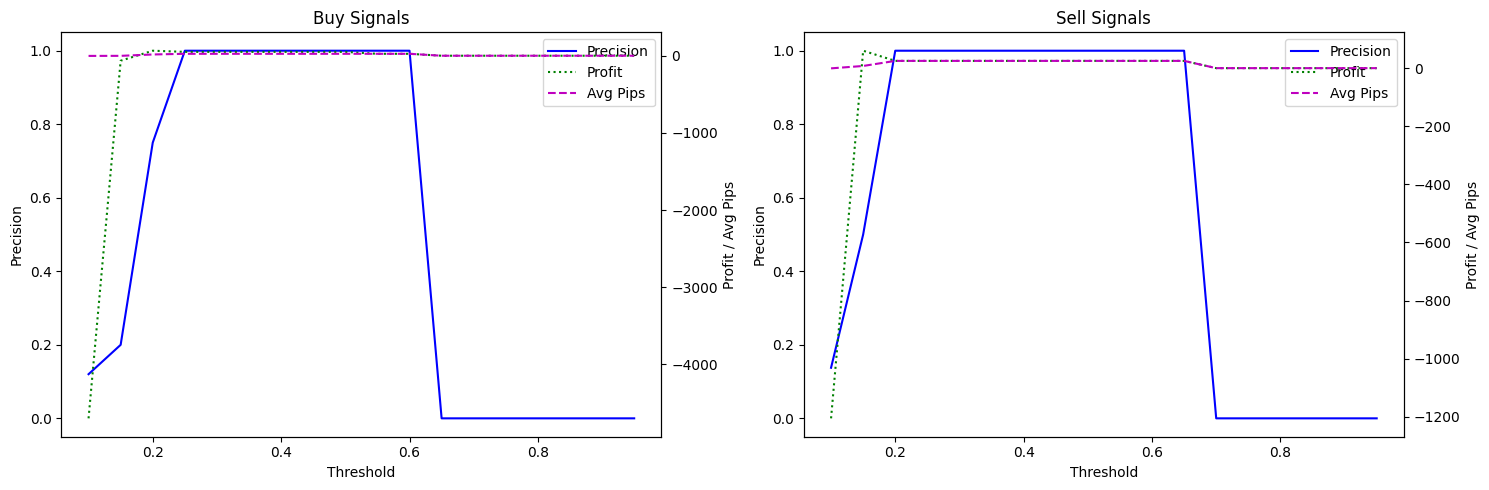

Mejor umbral para Compras (max profit ajustado por costo=0.2): 0.20 (Profit Ajustado: 64.20)
Mejor umbral para Ventas (max profit ajustado por costo=0.2): 0.15 (Profit Ajustado: 58.40)

Métricas Mensuales para Compras (Umbral seleccionado: 0.20):


,avg_pips,precision,profit,total_trades
month,,,,
2024-01,25.00,100.00%,25,1
2024-09,-10.00,0.00%,-10,1
2024-11,25.00,100.00%,50,2



Métricas Mensuales para Ventas (Umbral seleccionado: 0.15):


,avg_pips,precision,profit,total_trades
month,,,,
2024-01,7.50,50.00%,15,2
2024-08,-10.00,0.00%,-20,2
2024-09,25.00,100.00%,50,2
2024-11,7.50,50.00%,15,2


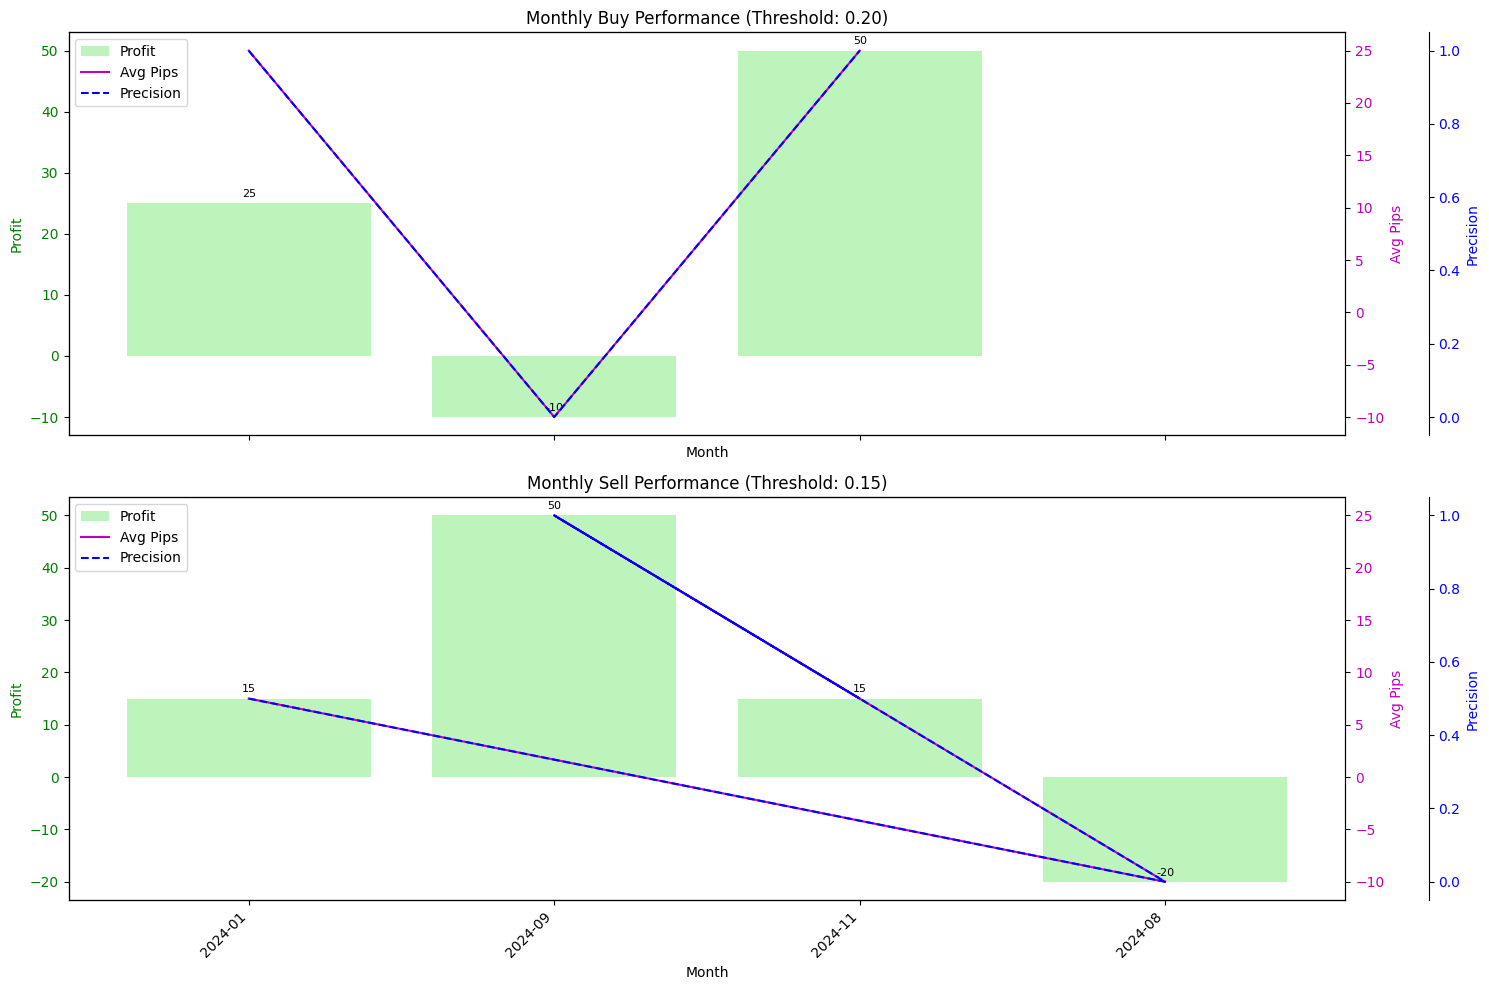


--- Winners Analysis Results ---

Best BUY (Max Profit): Thresh=0.20, Profit=65, Prec=75.00%, Trades=4.0

Best SELL (Max Profit): Thresh=0.15, Profit=60, Prec=50.00%, Trades=8.0


In [26]:
# --- Evaluacion por Umbrales (Dual Model + Winner Takes All) ---

print("Analyzing performance: Dual Model + Probability Calibration + Winner Takes All...")
import numpy as np
import pandas as pd
from utils.viz_utils import analizar_metricas_por_umbral

try:
    # 1. Obtener Probabilidades Crudas
    prob_buy = pipeline_buy.predict_proba(X_test_eval)[:, 1]
    prob_sell = pipeline_sell.predict_proba(X_test_eval)[:, 1]

    # 2. APLICAR LÓGICA "WINNER TAKES ALL"
    print("   Applying 'Winner Takes All' logic...")
    
    # Si Prob(Buy) > Prob(Sell), Sell = 0. Y viceversa.
    final_prob_buy = np.where(prob_buy > prob_sell, prob_buy, 0.0)
    final_prob_sell = np.where(prob_sell > prob_buy, prob_sell, 0.0)
    
    # 3. Construir Matriz para viz_utils
    n_samples = len(final_prob_buy)
    y_pred_proba_combined = np.zeros((n_samples, 3))
    y_pred_proba_combined[:, 1] = final_prob_buy  
    y_pred_proba_combined[:, 2] = final_prob_sell
    y_pred_proba_combined[:, 0] = 1 - (final_prob_buy + final_prob_sell) 

    # 4. Alinear y Analizar
    df_test_aligned = df_test.loc[X_test_eval.index].copy()
    
    compra_df, venta_df, compra_mensual_df, venta_mensual_df = analizar_metricas_por_umbral(
        y_pred_proba=y_pred_proba_combined,
        df_test=df_test_aligned,
        pip_objetivo=PIPS_OBJETIVO_GENERACION,
        pip_stop=PIPS_STOP_GENERACION,
        pip_sin_alcance=PIPS_SIN_ALCANCE_VALOR
    )

    # 5. Resultados
    print("\n--- Winners Analysis Results ---")
    
    def show_best(df, label):
        if not df.empty and 'profit' in df.columns:
            best = df.loc[df['profit'].idxmax()]
            print(f"\nBest {label} (Max Profit): Thresh={best.get('threshold'):.2f}, Profit={best.get('profit'):,.0f}, Prec={best.get('precision'):.2%}, Trades={best.get('total_trades')}")
    
    show_best(compra_df, "BUY")
    show_best(venta_df, "SELL")
    
except Exception as e:
    print(f"Error: {e}")

# Guardar el Modelo Entrenado

Guardar el objeto Pipeline entrenado completo en un archivo usando `joblib.dump`. Esto permite recargar el pipeline más tarde para hacer predicciones sobre nuevos datos sin necesidad de reentrenar.

In [18]:
# --- Reemplazar contenido de la celda 12f4e2fc ---

import os
import joblib
import json
import traceback

print("--- Model Saving Cell ---")

# Verificar si el modelo fue cargado o recién entrenado (variable definida en celda 7c0ee38a)
if 'model_loaded' in locals() and model_loaded:
    print("Model was loaded from existing files. Skipping saving.")
else:
    # Proceder a guardar solo si se entrenó un nuevo modelo
    print("Model was newly trained. Attempting to save pipeline, clusterer, and metadata...")

    # Verificar que las variables a guardar existan y no sean None
    # Estas variables DEBEN haber sido creadas en la celda 7c0ee38a si model_loaded es False
    if 'simplified_pipeline' not in locals() or simplified_pipeline is None:
        print("Error: 'simplified_pipeline' not found or is None. Cannot save.")
    elif 'fitted_clusterer' not in locals() or fitted_clusterer is None:
        print("Error: 'fitted_clusterer' not found or is None. Cannot save.")
    elif 'metadata' not in locals() or metadata is None:
        # 'metadata' ya debe contener las listas de features si se entrenó
        print("Error: 'metadata' dictionary (prepared during training) not found or is None. Cannot save.")
    else:
        try:
            # Asegurar que el directorio exista (model_dir definido en celda 7c0ee38a)
            os.makedirs(model_dir, exist_ok=True)

            # 1. Guardar el pipeline (model_filepath definido en celda 7c0ee38a)
            joblib.dump(simplified_pipeline, model_filepath)
            print(f"  - Pipeline saved successfully to: {model_filepath}")

            # 2. Guardar el clusterer ajustado (clusterer_filepath definido en celda 7c0ee38a)
            joblib.dump(fitted_clusterer, clusterer_filepath)
            print(f"  - Fitted clusterer saved successfully to: {clusterer_filepath}")

            # 3. Guardar metadata (usar el diccionario 'metadata' ya preparado en la celda 7c0ee38a)
            # Este diccionario ya contiene las listas 'final_numerical_features', etc.
            # (metadata_filepath definido en celda 7c0ee38a)
            with open(metadata_filepath, 'w') as f:
                json.dump(metadata, f, indent=4) # Guardar el diccionario 'metadata' existente
            print(f"  - Metadata saved successfully to: {metadata_filepath}")

            print("\nModel, clusterer, and metadata saved successfully.")

        except NameError as ne:
             print(f"Error saving: A required variable (like model_dir, model_filepath, etc.) might not be defined. {ne}")
             traceback.print_exc()
        except Exception as e:
            print(f"\nError saving the pipeline, clusterer, or metadata: {e}")
            traceback.print_exc()

# Mensaje final de la celda
print("--- Model Saving Cell Finished ---")

# Comentario: El código de ejemplo para cargar se mantiene igual
# Example of how to load the pipeline and clusterer later:
# loaded_pipeline = joblib.load(model_filepath)
# loaded_clusterer = joblib.load(clusterer_filepath)
# with open(metadata_filepath, 'r') as f:
#     loaded_metadata = json.load(f)
# print("Pipeline, clusterer and metadata loaded successfully.")
# # Remember to apply the SAME feature engineering steps before predicting
# # X_new_engineered, _ = engineer_features(X_new_raw,
# #                                         n_candles=loaded_metadata['n_candles_param'],
# #                                         n_clusters=loaded_metadata['n_clusters_param'],
# #                                         clusterer=loaded_clusterer,
# #                                         fit_clusterer=False)
# # new_predictions = loaded_pipeline.predict(X_new_engineered)


--- Model Saving Cell ---
Model was newly trained. Attempting to save pipeline, clusterer, and metadata...
  - Pipeline saved successfully to: ../models\forex_rf_pipeline_eurusd_5min.joblib
  - Fitted clusterer saved successfully to: ../models\forex_candle_clusterer_eurusd_5min.joblib
  - Metadata saved successfully to: ../models\forex_rf_pipeline_eurusd_5min_metadata.json

Model, clusterer, and metadata saved successfully.
--- Model Saving Cell Finished ---


# Evaluar Rendimiento en Conjunto Out-of-Time (OOT)

Aplicar la ingeniería de características al conjunto OOT usando el `fitted_clusterer` y evaluar el rendimiento del `simplified_pipeline` final en estos datos no vistos durante el entrenamiento ni la validación inicial. Esto da una estimación más realista del rendimiento futuro.

--- OOT Evaluation Cell ---

Applying feature engineering to OOT set (X_oot)...
--- Starting Feature Engineering ---
>>> Starting step: apply_technical_indicators


c:\Users\Administrador\Documents\Proyectos\Trading\ForexDataExtractorProject\src\utils\exploration_utils.py:1012: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f"{base_name}_shrinking_histogram_above_zero"] = (
c:\Users\Administrador\Documents\Proyectos\Trading\ForexDataExtractorProject\src\utils\exploration_utils.py:1019: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f"{base_name}_buy_signal"] = (
c:\Users\Administrador\Documents\Proyectos\Trading\ForexDataExtractorProject\src\utils\exploration_utils.py:1024: PerformanceW

<<< Finished step: apply_technical_indicators
>>> Starting step: apply_candle_features (n_candles=15)
<<< Finished step: apply_candle_features
   Transforming with PROVIDED CandleClusterer...
>>> Starting step: CandleClusterer.transform
   Candle clusters predicted.


c:\Users\Administrador\Documents\Proyectos\Trading\ForexDataExtractorProject\src\utils\exploration_utils.py:626: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  result_df[f'{feature}_lag{i}'] = df[feature].shift(i)
c:\Users\Administrador\Documents\Proyectos\Trading\ForexDataExtractorProject\src\utils\exploration_utils.py:626: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  result_df[f'{feature}_lag{i}'] = df[feature].shift(i)
c:\Users\Administrador\Documents\Proyectos\Trading\ForexDataExtractorProject\src\utils\exploration_utils.py:

   Basic patterns created.
   No pattern mapping to apply (or mapping is empty).
<<< Finished step: CandleClusterer.transform
>>> Starting step: replace_inf_with_nan
  Columns initially identified as numeric: ['open', 'high', 'low', 'close', 'volume', 'barCount', 'Year', 'Day', 'Hour', 'Minute', 'DayOfWeek', 'compra_velas', 'compra_pips', 'venta_velas', 'venta_pips', 'SMA_10', 'SMA_40', 'SMA_100', 'diff_SMA_10_SMA_40', 'ratio_SMA_10_SMA_40', 'ratio_SMA_40_SMA_10', 'diff_SMA_10_SMA_100', 'ratio_SMA_10_SMA_100', 'ratio_SMA_100_SMA_10', 'diff_SMA_40_SMA_100', 'ratio_SMA_40_SMA_100', 'ratio_SMA_100_SMA_40', 'sma_order_score', 'slope_SMA_10', 'slope_SMA_40', 'slope_SMA_100', 'diff_slope_SMA_10_slope_SMA_40', 'diff_slope_SMA_10_slope_SMA_100', 'diff_slope_SMA_40_slope_SMA_100', 'norm_diff_SMA_10_SMA_100', 'norm_diff_SMA_40_SMA_100', 'close_diff_SMA_10', 'close_diff_SMA_40', 'close_diff_SMA_100', 'crossover', 'sma_spread', 'acc_SMA_10', 'acc_SMA_40', 'acc_SMA_100', 'SMA_10_momentum', 'SMA_10_

,threshold,precision,total_trades,profit,avg_pips
0,0.10,15.84%,"13,399",609,0.05
1,0.15,16.98%,"12,229","2,336",0.19
2,0.20,17.90%,"11,171","3,109",0.28
3,0.25,19.09%,"9,891","3,586",0.36
4,0.30,21.06%,"8,138","3,872",0.48
5,0.35,22.81%,"6,559","3,716",0.57
6,0.40,24.62%,"5,446","3,779",0.69
7,0.45,27.07%,"4,522","3,996",0.88
8,0.50,29.48%,"3,579","3,834",1.07
9,0.55,34.09%,"2,479","3,699",1.49



Sell Strategy Metrics:


,threshold,precision,total_trades,profit,avg_pips
0,0.10,16.28%,"13,628","1,401",0.10
1,0.15,17.48%,"12,472","3,019",0.24
2,0.20,18.57%,"11,248","3,753",0.33
3,0.25,20.33%,"9,766","4,456",0.46
4,0.30,21.99%,"8,300","4,602",0.55
5,0.35,23.80%,"6,913","4,522",0.65
6,0.40,25.71%,"5,760","4,535",0.79
7,0.45,27.98%,"4,761","4,626",0.97
8,0.50,31.38%,"3,716","4,745",1.28
9,0.55,36.26%,"2,639","4,547",1.72


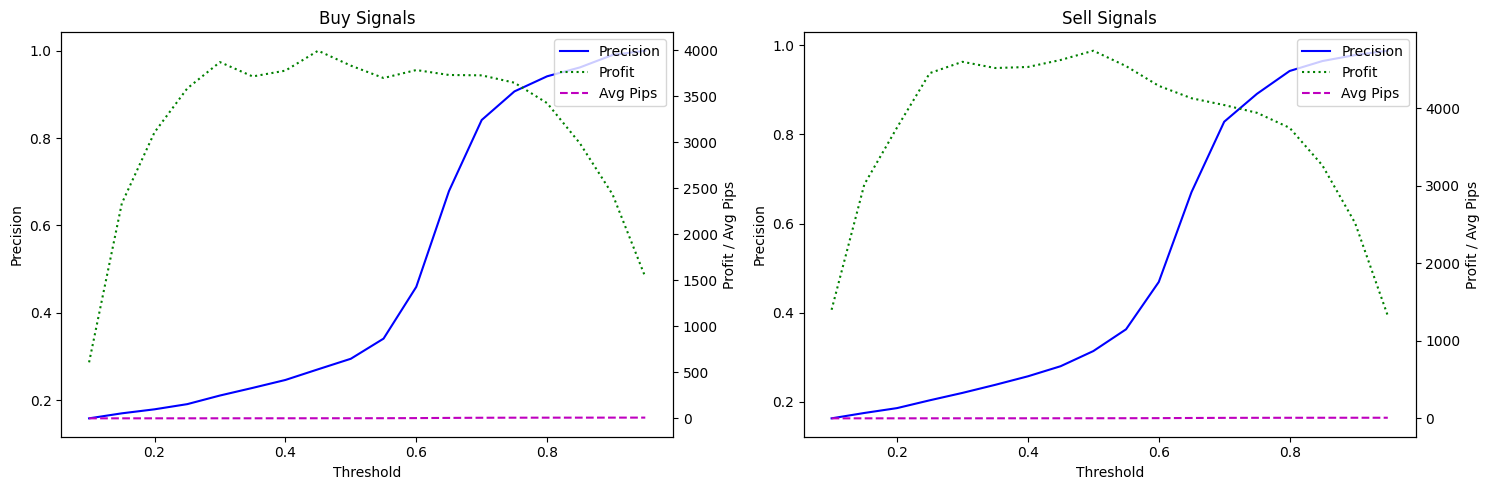

Mejor umbral para Compras (max profit ajustado por costo=0.2): 0.70 (Profit Ajustado: 3611.96)
Mejor umbral para Ventas (max profit ajustado por costo=0.2): 0.55 (Profit Ajustado: 4018.84)

Métricas Mensuales para Compras (Umbral seleccionado: 0.70):


,avg_pips,precision,profit,total_trades
month,,,,
2025-01,5.98,79.49%,700,117
2025-02,5.94,79.37%,374,63
2025-03,5.62,76.00%,984,175
2025-04,7.42,94.22%,"1,670",225



Métricas Mensuales para Ventas (Umbral seleccionado: 0.55):


,avg_pips,precision,profit,total_trades
month,,,,
2025-01,1.41,33.17%,866,615
2025-02,1.09,29.42%,642,588
2025-03,1.09,30.18%,"1,030",941
2025-04,4.06,59.80%,"2,010",495


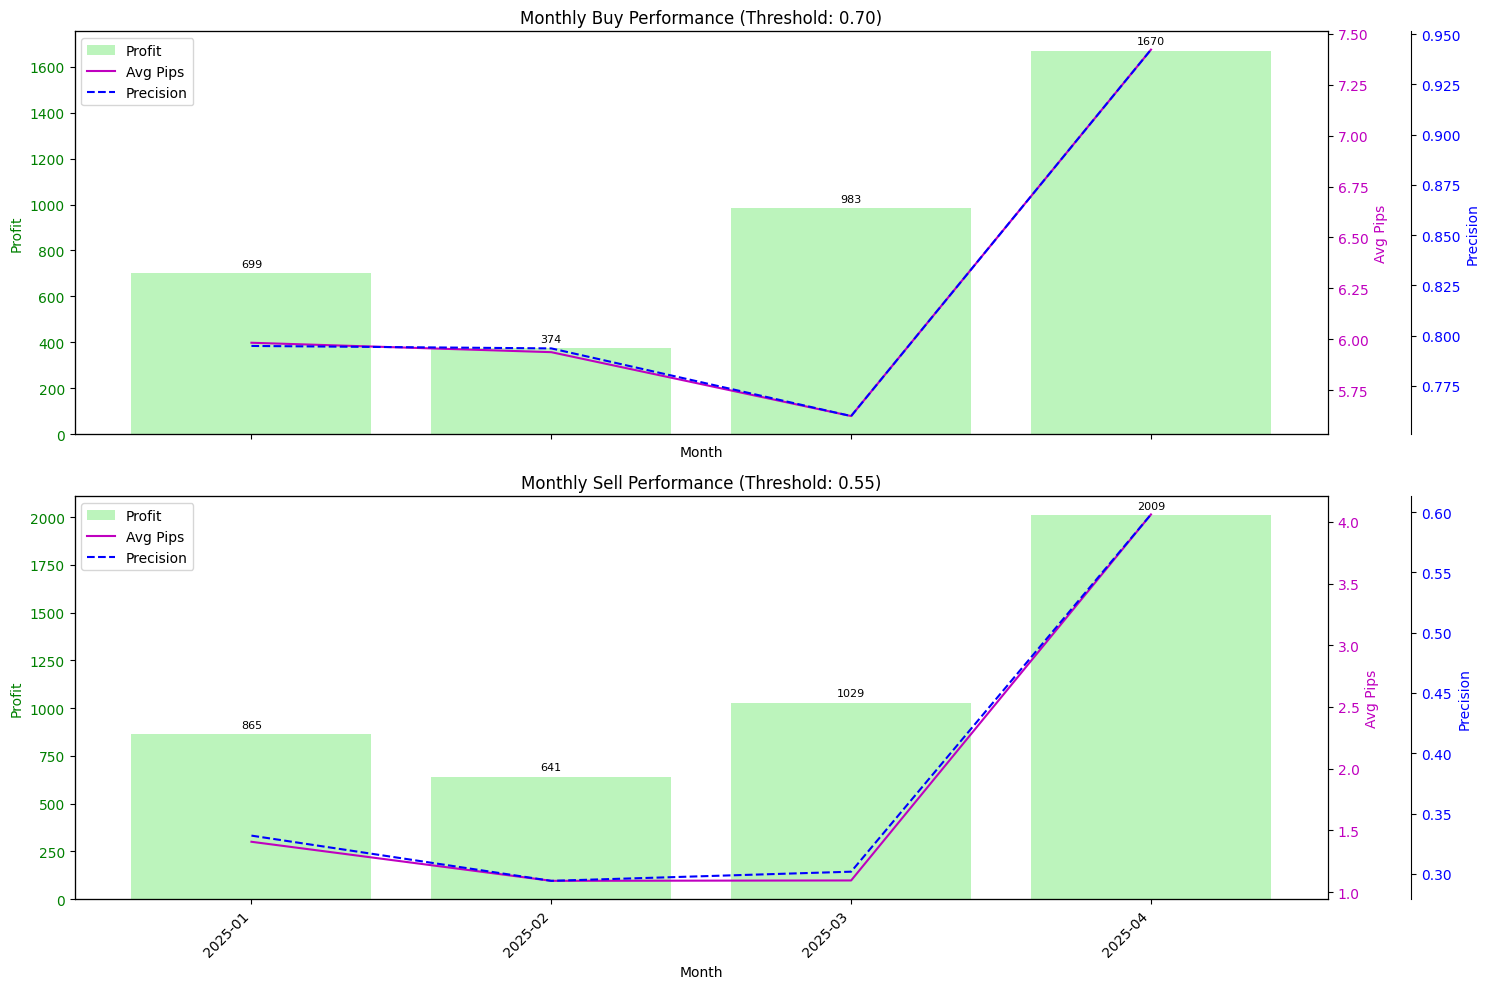

   OOT Threshold analysis function completed.

--- OOT Evaluation Cell Finished ---


In [22]:
# --- Celda para Evaluación OOT ---
import utils.viz_utils
importlib.reload(utils.viz_utils)
from utils.viz_utils import analizar_metricas_por_umbral
import traceback
from sklearn.metrics import classification_report, accuracy_score
# Asegúrate que la función de análisis esté disponible si la vas a usar
# from utils.viz_utils import analizar_metricas_por_umbral

print("--- OOT Evaluation Cell ---")

try:
    # --- Verificar existencia de variables necesarias ---
    required_vars_oot = ['simplified_pipeline', 'fitted_clusterer', 'X_oot', 'y_oot', 'df_oot',
                         'N_CANDLES_PARAM', 'N_CLUSTERS_PARAM',
                         'PIPS_OBJETIVO_GENERACION', 'PIPS_STOP_GENERACION', 'PIPS_SIN_ALCANCE_VALOR']
    for var_name in required_vars_oot:
        if var_name not in locals():
            raise NameError(f"Variable OOT '{var_name}' not found. Ensure previous cells ran correctly.")

    # --- 1. Aplicar Ingeniería de Características a X_oot ---
    print("\nApplying feature engineering to OOT set (X_oot)...")
    X_engineered_oot, _ = engineer_features(
        X_oot,
        n_candles=N_CANDLES_PARAM,
        n_clusters=N_CLUSTERS_PARAM,
        clusterer=fitted_clusterer, # Usar el clusterer ajustado
        fit_clusterer=False       # NO reajustar
    )
    print(f"Shape after external engineering (OOT): {X_engineered_oot.shape}")

    # --- 2. Alinear y_oot ---
    # Alinear y_oot con las filas que sobrevivieron a la ingeniería
    y_oot_aligned = y_oot.loc[X_engineered_oot.index]
    print(f"Shape of y_oot_aligned: {y_oot_aligned.shape}")

    # --- 3. Evaluar usando el Pipeline Simplificado (Predicciones y Métricas) ---
    print("\nEvaluating model performance on OOT set using simplified pipeline...")

    # Predecir clases en conjunto OOT (ingenierizado)
    y_pred_oot = simplified_pipeline.predict(X_engineered_oot)
    acc_oot = accuracy_score(y_oot_aligned, y_pred_oot)

    print("\n=== Reporte de Clasificación - Conjunto OOT ===\n")
    print(f"Length check: y_oot_aligned={len(y_oot_aligned)}, y_pred_oot={len(y_pred_oot)}")
    if len(y_oot_aligned) == len(y_pred_oot):
        print(classification_report(y_oot_aligned, y_pred_oot))
        print(f"Accuracy OOT: {acc_oot:.4f}\n")
    else:
        print("Error: Length mismatch between y_oot_aligned and y_pred_oot. Cannot generate report.")


    # --- 4. (Opcional) Análisis por Umbral de Probabilidad en OOT ---
    print("\nPredicting probabilities on OOT set for threshold analysis...")
    y_pred_proba_oot = simplified_pipeline.predict_proba(X_engineered_oot)
    class_labels_oot = simplified_pipeline.classes_ # Deberían ser las mismas
    print(f"   Model classes order (OOT check): {class_labels_oot}")

    # Preparar df_oot alineado
    print("   Aligning OOT data (df_oot) for analysis...")
    required_analysis_cols_oot = ['compra_resultado', 'venta_resultado', 'compra_pips', 'venta_pips', 'datetime']
    if not all(col in df_oot.columns for col in required_analysis_cols_oot):
         raise ValueError(f"Error: df_oot is missing required columns for threshold analysis: {required_analysis_cols_oot}")

    df_oot_aligned = df_oot.loc[X_engineered_oot.index].copy()

    if len(df_oot_aligned) != len(y_pred_proba_oot):
        raise ValueError(f"Mismatch in lengths for OOT analysis: df_oot_aligned ({len(df_oot_aligned)}) vs y_pred_proba_oot ({len(y_pred_proba_oot)})")
    print(f"   Aligned OOT data shape: {df_oot_aligned.shape}")

    print("\n   Running threshold analysis function on OOT data...")
    print(f"   Using pip_objetivo={PIPS_OBJETIVO_GENERACION}, pip_stop={PIPS_STOP_GENERACION}, pip_sin_alcance={PIPS_SIN_ALCANCE_VALOR:.4f} for OOT analysis.")

    # Asegúrate que la función esté importada
    from utils.viz_utils import analizar_metricas_por_umbral

    # Ejecutar análisis (esto también mostrará tablas y gráficos para OOT)
    compra_df_oot, venta_df_oot, compra_mensual_df_oot, venta_mensual_df_oot = analizar_metricas_por_umbral(
        y_pred_proba=y_pred_proba_oot,
        df_test=df_oot_aligned, # Pasar el dataframe OOT alineado
        pip_objetivo=PIPS_OBJETIVO_GENERACION,
        pip_stop=PIPS_STOP_GENERACION,
        pip_sin_alcance=PIPS_SIN_ALCANCE_VALOR,
        # class_labels=class_labels_oot # Descomentar si la función lo soporta
    )
    print("   OOT Threshold analysis function completed.")


except NameError as ne:
     print(f"\nERROR in OOT Evaluation: A required variable might not be defined. {ne}")
     traceback.print_exc()
except ValueError as ve:
     print(f"\nERROR in OOT Evaluation: ValueError occurred. {ve}")
     traceback.print_exc()
except ImportError as ie:
     print(f"\nERROR in OOT Evaluation: ImportError. Could not import a required function (e.g., 'analizar_metricas_por_umbral'). {ie}")
     traceback.print_exc()
except Exception as e:
    print(f"\nAn unexpected error occurred during OOT evaluation: {e}")
    traceback.print_exc()

print("\n--- OOT Evaluation Cell Finished ---")